In [14]:
import pandas as pd
import numpy as np
from pathlib import Path
print("Libraries imported successfully!")

DATA_PATH = Path("../data/processed/train.csv")
train_df = pd.read_csv(DATA_PATH)
print("Training dataset loaded successfully!")
print("Dataset shape:", train_df.shape)
train_df.head()

print("Dataset information:")
print(train_df.info())
print("\nSentiment distribution:")
print(train_df["sentiment"].value_counts())
print("\nMissing values:")
print(train_df.isnull().sum())

Libraries imported successfully!
Training dataset loaded successfully!
Dataset shape: (40000, 3)
Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   review         40000 non-null  str  
 1   sentiment      40000 non-null  str  
 2   review_length  40000 non-null  int64
dtypes: int64(1), str(2)
memory usage: 937.6 KB
None

Sentiment distribution:
sentiment
positive    20000
negative    20000
Name: count, dtype: int64

Missing values:
review           0
sentiment        0
review_length    0
dtype: int64


In [15]:
import re
import html
def remove_html_tags(text):
    text = re.sub(r"<[^>]+>", " ", text)
    text = html.unescape(text)
    text = re.sub(r"\s+", " ", text).strip()
    return text
train_df["cleaned_review"] = train_df["review"].apply(remove_html_tags)
print("HTML preprocessing completed!")
for i in range(3):
    print(f"\nREVIEW {i+1}")
    print("\nBEFORE:")
    print(train_df["review"].iloc[i][:500])
    print("\nAFTER:")
    print(train_df["cleaned_review"].iloc[i][:500])
    print("-" * 80)

HTML preprocessing completed!

REVIEW 1

BEFORE:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

AFTER:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me. The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the clas

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer()
print("CountVectorizer initialised")
X_train = vectorizer.fit_transform(train_df["cleaned_review"])
print("Vectorisation completed!")
print("Feature matrix shape:", X_train.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))
print("First 30 vocabulary words:")
vocabulary_words = list(vectorizer.vocabulary_.keys())
print(vocabulary_words[:30])
feature_names = vectorizer.get_feature_names_out()
sample_matrix = X_train[:3].toarray()
sample_df = pd.DataFrame(sample_matrix,columns=feature_names)
print("Numerical representation of the first 3 reviews:")
print(sample_df.loc[:, sample_df.sum(axis=0) > 0])


CountVectorizer initialised
Vectorisation completed!
Feature matrix shape: (40000, 92544)
Vocabulary size: 92544
First 30 vocabulary words:
['one', 'of', 'the', 'other', 'reviewers', 'has', 'mentioned', 'that', 'after', 'watching', 'just', 'oz', 'episode', 'you', 'll', 'be', 'hooked', 'they', 'are', 'right', 'as', 'this', 'is', 'exactly', 'what', 'happened', 'with', 'me', 'first', 'thing']
Numerical representation of the first 3 reviews:
   about  accustomed  actors  addiction  after  agenda  agreements  air  all  \
0      1           1       0          0      1       1           1    0    1   
1      1           0       1          0      0       0           0    0    2   
2      0           0       0          1      0       0           0    1    0   

   allen  ...  woody  word  worth  would  wouldn  written  years  you  young  \
0      0  ...      0     2      0      1       1        0      0    3      0   
1      0  ...      0     0      1      0       0        1      0    1      0 

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
print("Model libraries imported successfully!")
X = train_df["cleaned_review"]
y = train_df["sentiment"]
X_train_model, X_val, y_train_model, y_val = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Model training reviews:", len(X_train_model))
print("Validation reviews:", len(X_val))
print("\nTraining distribution:")
print(y_train_model.value_counts())
print("\nValidation distribution:")
print(y_val.value_counts())
baseline_model = Pipeline([("vectorizer", CountVectorizer()), ("classifier", LogisticRegression(max_iter=1000, random_state=42))])
baseline_model.fit(X_train_model, y_train_model)
print("Logistic Regression model trained successfully!")
y_pred = baseline_model.predict(X_val)
print("Predictions generated successfully!")
print("\nFirst 10 predictions:")
print(y_pred[:10])
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report)
y_prob = baseline_model.predict_proba(X_val)[:, 1]
accuracy = accuracy_score(y_val, y_pred)
precision = precision_score(y_val, y_pred, pos_label="positive")
recall = recall_score(y_val, y_pred, pos_label="positive")
f1 = f1_score(y_val, y_pred, pos_label="positive")
roc_auc = roc_auc_score((y_val == "positive").astype(int),y_prob)
print("BASELINE MODEL PERFORMANCE")
print("-" * 40)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_val, y_pred))

Model libraries imported successfully!
Model training reviews: 32000
Validation reviews: 8000

Training distribution:
sentiment
negative    16000
positive    16000
Name: count, dtype: int64

Validation distribution:
sentiment
positive    4000
negative    4000
Name: count, dtype: int64
Logistic Regression model trained successfully!
Predictions generated successfully!

First 10 predictions:
['positive' 'negative' 'positive' 'positive' 'positive' 'negative'
 'negative' 'positive' 'positive' 'negative']
BASELINE MODEL PERFORMANCE
----------------------------------------
Accuracy:  0.8855
Precision: 0.8792
Recall:    0.8938
F1-Score:  0.8864
ROC-AUC:   0.9515

Classification Report:
              precision    recall  f1-score   support

    negative       0.89      0.88      0.88      4000
    positive       0.88      0.89      0.89      4000

    accuracy                           0.89      8000
   macro avg       0.89      0.89      0.89      8000
weighted avg       0.89      0.89      0

Confusion Matrix:
[[3509  491]
 [ 425 3575]]


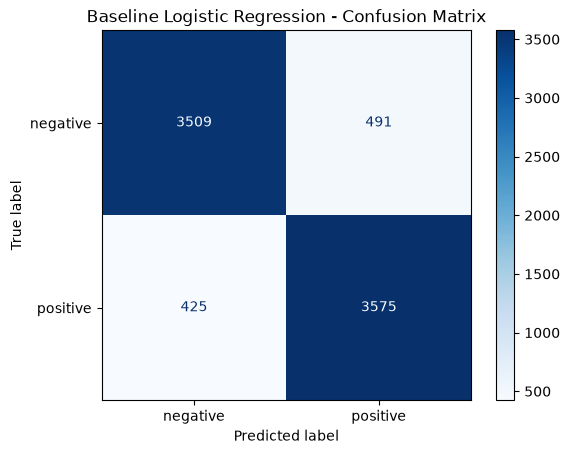

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
labels = ["negative", "positive"]
cm = confusion_matrix(y_val, y_pred, labels=labels)
print("Confusion Matrix:")
print(cm)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
display.plot(cmap="Blues", values_format="d")
plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.show()


In [19]:
import joblib
from pathlib import Path
results_dir = Path("../results")
models_dir = results_dir / "models"
figures_dir = results_dir / "figures"
models_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(baseline_model, models_dir / "baseline_logistic_regression.pkl")
baseline_results = pd.DataFrame([{
    "model": "Logistic Regression",
    "vectorizer": "CountVectorizer",
    "preprocessing": "HTML removal",
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": roc_auc
}])
baseline_results.to_csv(results_dir / "baseline_metrics.csv", index=False)
print("Baseline model and metrics saved!")

Baseline model and metrics saved!
